# Test opponent-map display conversion
Set the HDF5 path and frame index below, then run all cells. Only the selected frame's normalization window is loaded. The plots compare the original signed channel values with the uint8 display values; these are not natural RGB colors.

Uses Geoff's [rolling-window instructions](https://upennvisionlabs.slack.com/archives/C08D870F54P/p1793712750563809).

In [1]:
from pathlib import Path
import sys
import h5py
import numpy as np
import matplotlib.pyplot as plt

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents]
                    if (path / "code/library/sensor_utility/world_util.py").exists())
sys.path.insert(0, str(project_root / "code/library/sensor_utility"))
import world_util
import sensors_utility

In [2]:
hdf5_path = Path("/Volumes/FLIC_processing/NEWscriptedIndoorOutdoorVideos2026/FLIC_20/walkOutdoor/GKA/1/W/transformed.hdf5")
raw_chunks_path = Path("/Volumes/FLIC_raw/NEWscriptedIndoorOutdoorVideos2026/FLIC_20/walkOutdoor/GKA/1")  # Set the directory containing world and MS chunks.
frame_index = 5836  # Verified L+M coverage in this recording.
fps = 120.0  # Recording and playback rate (frames per second)
window_seconds = 1.0


Loading world chunks:   0%|          | 0/47 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

Averaging opponent frames:   0%|          | 0/1000 [00:00<?, ?it/s]

... (47 outputs left out)

Local copy of ToolboxToolbox out of date (or you made local modifications).
Consider updating with git pull or otherwise synchronizing.



Updating "ToolboxRegistry".
Already up to date.
Updating "lightLoggerAnalysis".
Already up to date.
Updating "combiLEDToolbox".
Already up to date.
Updating "BrainardLabToolbox".
Already up to date.
Updating "WatsonYellott2012_PupilSize".
Already up to date.
Updating "bads".
Already up to date.
Updating "export_fig".
Already up to date.
Updating "Psychtoolbox-3".
Already up to date.
Updating "SilentSubstitutionToolbox".
Already up to date.
Updating "ExampleTestToolbox".
Already up to date.
Updating "isetcam".
Already up to date.
Updating "isetbio".
Already up to date.
Resetting path to factory state.
Adding "ToolboxToolbox" to path at "/Users/zacharykelly/Documents/MATLAB/ToolboxToolbox".
Adding "lightLoggerAnalysis" to path at "/Users/zacharykelly/Documents/MATLAB/projects/lightLoggerAnalysis".
Adding "combiLEDToolbox" to path at "/Users/zacharykelly/Documents/MATLAB/toolboxes/combiLEDToolbox/code".
Adding "BrainardLabToolbox" to path at "/Users/zacharykelly/Documents/MATLAB/toolboxes

  Local hook template more recent than local hook. Consider updating.


Locating project "lightLoggerAnalysis" within "/Users/zacharykelly/Documents/MATLAB/projects".
  Found at "/Users/zacharykelly/Documents/MATLAB/projects/lightLoggerAnalysis".
Locating project "lightLogger" within "/Users/zacharykelly/Documents/MATLAB/projects".
  Found at "/Users/zacharykelly/Documents/MATLAB/projects/lightLogger".
Locating project "combiExperiments" within "/Users/zacharykelly/Documents/MATLAB/projects".
  Found at "/Users/zacharykelly/Documents/MATLAB/projects/combiExperiments".
Locating project "lightLoggerAnalysis" within "/Users/zacharykelly/Documents/MATLAB/projects".
  Found at "/Users/zacharykelly/Documents/MATLAB/projects/lightLoggerAnalysis".

FLIC_processing_dir = 

    "/Volumes/FLIC_processing"

  Hook success with status 0.
Checking for "combiLEDToolbox" local hook.
  Running local hook "/Users/zacharykelly/Documents/MATLAB/localHookFolder/combiLEDToolboxLocalHook.m".
  Hook success with status 0.
Checking for "BrainardLabToolbox" local hook.
Checking for

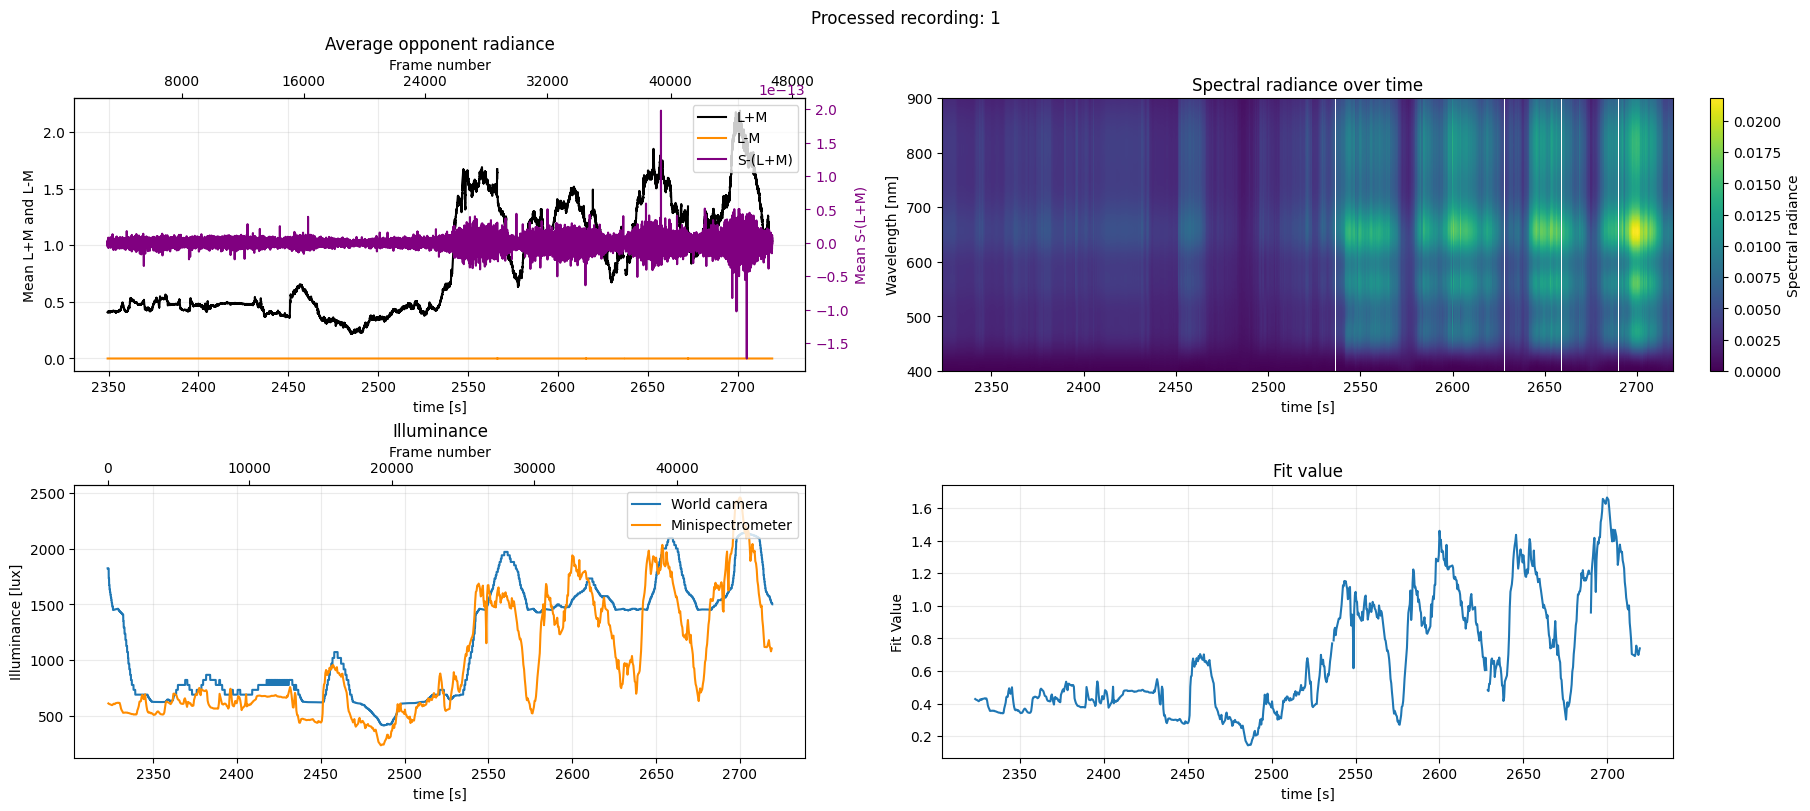

In [6]:


# The world file lives in W; its parent recording also contains M.
recording_directory = hdf5_path.expanduser().parent.parent
recording_figure, recording_axes = sensors_utility.plot_processed_recording(
    str(recording_directory), verbose=True, raw_directory=str(raw_chunks_path)
)
plt.show()


Loading world metadata chunks:   0%|          | 0/13 [00:00<?, ?it/s]

Loading world chunks:   0%|          | 0/13 [00:00<?, ?it/s]

Averaging world frames:   0%|          | 0/3600 [00:00<?, ?it/s]

Averaging world frames:   0%|          | 0/3600 [00:00<?, ?it/s]

Averaging world frames:   0%|          | 0/3600 [00:00<?, ?it/s]

Averaging world frames:   0%|          | 0/3600 [00:00<?, ?it/s]

... (6 outputs left out)

Averaging world frames:   0%|          | 0/3600 [00:00<?, ?it/s]

Averaging world frames:   0%|          | 0/3600 [00:00<?, ?it/s]

Averaging world frames:   0%|          | 0/3489 [00:00<?, ?it/s]

Loading raw MS chunks:   0%|          | 0/30 [00:00<?, ?it/s]

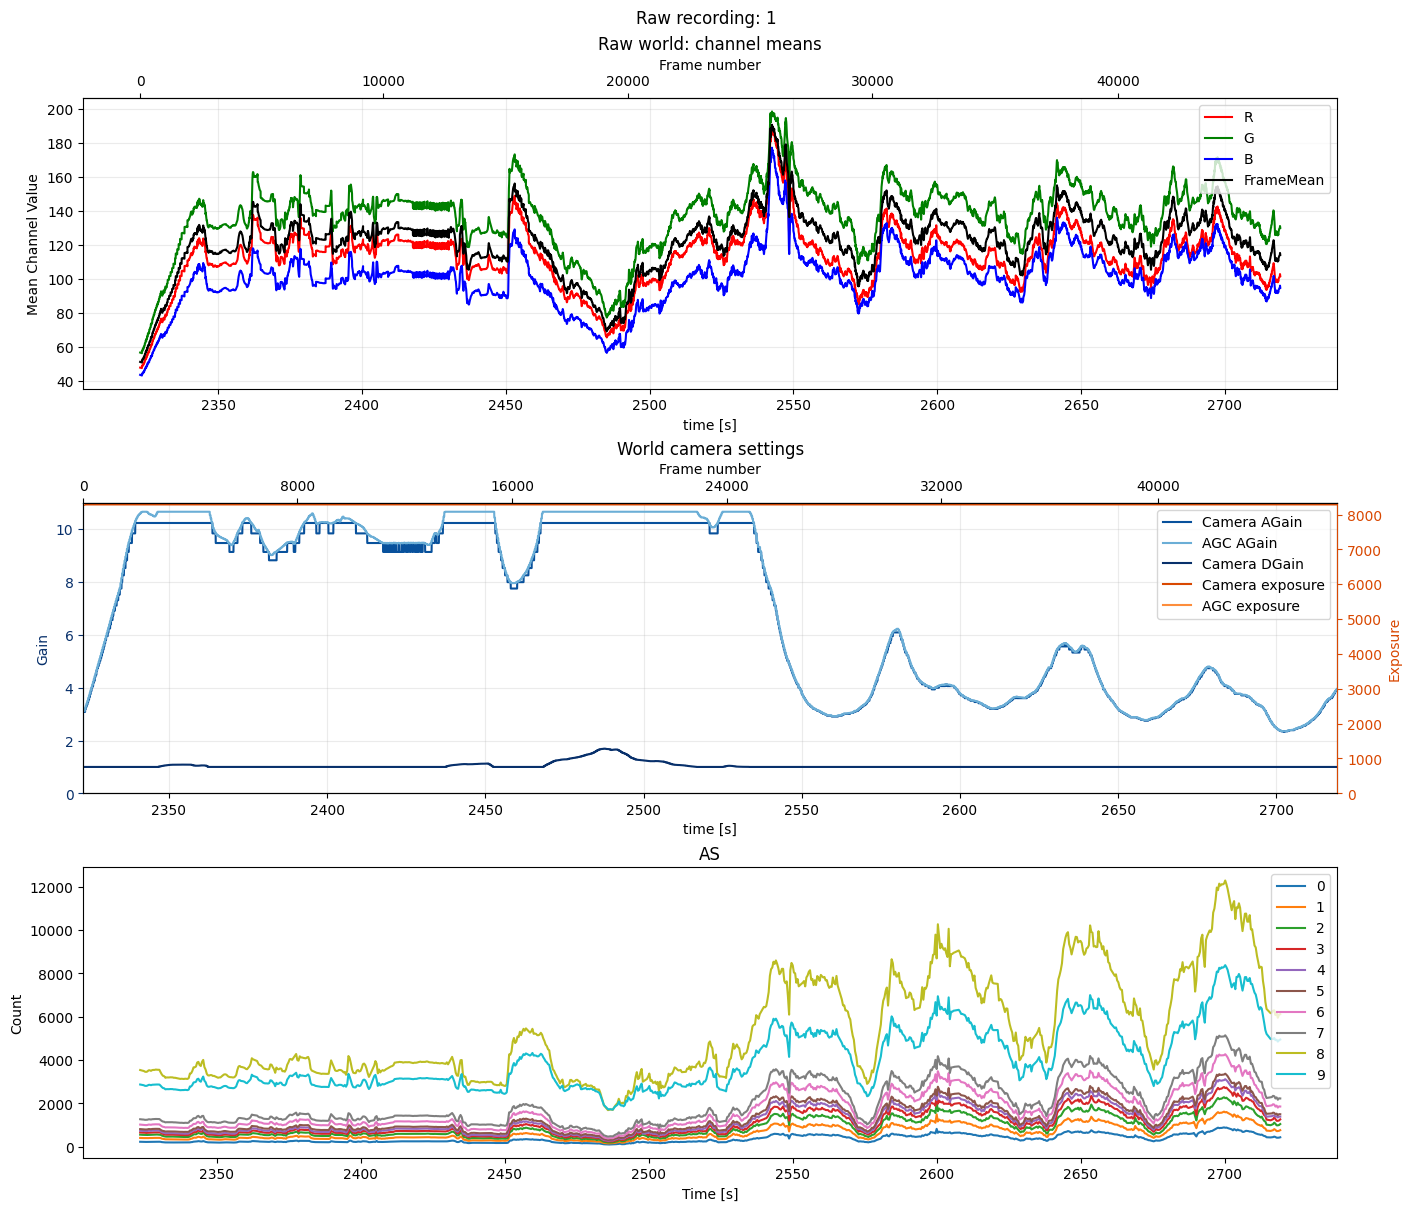

In [7]:
# Plot the raw world and MS chunks with progress reporting.
raw_figure, raw_axes = sensors_utility.plot_raw_recording(
    str(raw_chunks_path.expanduser()), verbose=True
)
plt.show()


In [ ]:
with h5py.File(hdf5_path.expanduser(), "r") as saved:
    frames = saved["data/frames"]
    assert 0 <= frame_index < len(frames), "frame_index is outside the recording."
    window_frames = min(len(frames), max(1, int(round(fps * window_seconds))))
    start = min(max(frame_index - window_frames // 2, 0), len(frames) - window_frames)
    opponentmaps = frames[start:start + window_frames]

converted_frames = world_util.opponentmap_to_videoframe(
    opponentmaps, fps=fps, window_seconds=window_seconds, verbose=True
)
selected = frame_index - start
before = opponentmaps[selected]
after = converted_frames[selected]
print(f"Loaded frames {start}:{start + window_frames}; output {converted_frames.shape}, {converted_frames.dtype}")


In [ ]:
# Export the recording as an L+M video with the visual-angle overlay.
sys.path.insert(0, str(project_root / "code/library/matlabIO/python_libraries"))
import video_io

output_path = Path.home() / "Desktop" / "opponentmap_lm_test.avi"
video_io.opponentmaps_to_video(
    str(hdf5_path), str(output_path),
    fill_missing_frames=True, verbose=True, overlay=True,
)
print(output_path)

Writing frames:   0%|          | 0/47574 [00:00<?, ?frame/s]

/Users/zacharykelly/Desktop/opponentmap_lm_test.avi
